# EDA — Personalized Health & Wellness Coaching for Corporate Employees
Level 1 (ML) exploratory data analysis on the synthetic cross-sectional dataset.

Run `python main.py --stage data` first if `data/raw/employee_wellness_cross_sectional.csv` doesn't exist yet.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
df = pd.read_csv("../data/raw/employee_wellness_cross_sectional.csv")
df.head()

,employee_id,age,gender,department,tenure_years,work_hours_per_week,sleep_hours,physical_activity_min_week,diet_score,screen_time_hours,caffeine_intake_mg,meditation_min_week,social_support_score,job_satisfaction_score,work_life_balance_score,past_medical_leaves,stress_level,burnout_risk
0,EMP00001,25,Male,Operations,5.8,40.1,7.55,0.0,5.2,7.23,321.9,13.5,6.0,6.0,9.9,1,32.4,0
1,EMP00002,51,Female,HR,5.7,36.5,6.94,195.3,7.1,5.91,387.2,7.8,6.3,9.3,8.9,2,29.1,0
2,EMP00003,46,Female,Engineering,3.9,54.3,6.87,0.0,8.2,9.14,574.2,29.6,6.5,8.2,7.3,1,43.8,0
3,EMP00004,38,Female,HR,4.6,32.4,5.18,177.4,6.2,3.83,194.1,83.2,6.7,6.8,10.0,0,24.6,1
4,EMP00005,38,Female,Support,0.7,53.4,8.30,88.8,9.2,5.91,200.1,42.2,6.8,4.7,9.6,2,56.6,0


In [2]:
df.info()
print()
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])

<class 'pandas.DataFrame'>
RangeIndex: 1205 entries, 0 to 1204
Data columns (total 18 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   employee_id                 1205 non-null   str    
 1   age                         1205 non-null   int64  
 2   gender                      1205 non-null   str    
 3   department                  1205 non-null   str    
 4   tenure_years                1205 non-null   float64
 5   work_hours_per_week         1205 non-null   float64
 6   sleep_hours                 1164 non-null   float64
 7   physical_activity_min_week  1169 non-null   float64
 8   diet_score                  1164 non-null   float64
 9   screen_time_hours           1205 non-null   float64
 10  caffeine_intake_mg          1205 non-null   float64
 11  meditation_min_week         1205 non-null   float64
 12  social_support_score        1161 non-null   float64
 13  job_satisfaction_score      1205 non-null   

In [3]:
df.describe()

,age,tenure_years,work_hours_per_week,sleep_hours,physical_activity_min_week,diet_score,screen_time_hours,caffeine_intake_mg,meditation_min_week,social_support_score,job_satisfaction_score,work_life_balance_score,past_medical_leaves,stress_level,burnout_risk
count,1205.000000,1205.000000,1205.000000,1164.000000,1169.000000,1164.000000,1205.000000,1205.000000,1205.000000,1161.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000
mean,40.646473,4.160166,45.965477,6.500550,123.923011,5.931014,6.983220,249.379751,24.933693,5.924203,6.200249,9.284813,1.231535,47.371452,0.419917
std,10.922690,2.621957,7.782243,1.109396,85.191906,1.737550,2.092583,119.364863,24.988194,1.904204,1.967390,0.847506,1.114090,12.271892,0.493750
min,22.000000,0.000000,30.000000,3.000000,0.000000,1.000000,1.000000,0.000000,0.100000,1.000000,1.000000,6.100000,0.000000,7.000000,0.000000
25%,31.000000,2.200000,40.400000,5.767500,61.800000,4.800000,5.600000,169.000000,6.900000,4.600000,4.900000,8.800000,0.000000,38.800000,0.000000
50%,41.000000,4.000000,45.700000,6.520000,114.600000,5.900000,6.940000,248.600000,17.500000,5.900000,6.200000,9.600000,1.000000,47.600000,0.000000
75%,50.000000,6.000000,50.800000,7.250000,183.300000,7.100000,8.400000,330.600000,35.500000,7.200000,7.600000,10.000000,2.000000,55.700000,1.000000
max,59.000000,12.600000,73.600000,9.000000,412.200000,10.000000,14.120000,625.100000,239.000000,10.000000,10.000000,10.000000,7.000000,88.000000,1.000000


## Target distributions

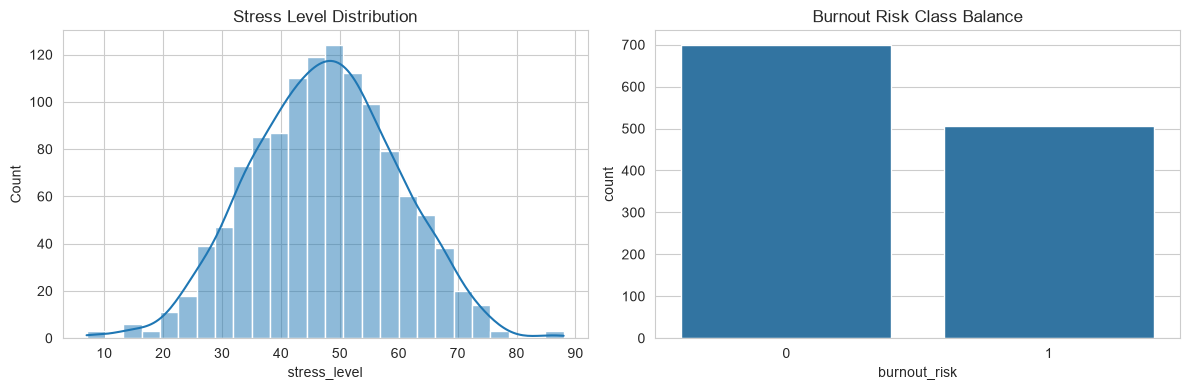

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["stress_level"], kde=True, ax=axes[0])
axes[0].set_title("Stress Level Distribution")

sns.countplot(x="burnout_risk", data=df, ax=axes[1])
axes[1].set_title("Burnout Risk Class Balance")
plt.tight_layout()
plt.show()

## Correlation with stress level

In [8]:
corr = df[numeric_cols].corr()["stress_level"].sort_values(ascending=False)

sns.countplot(x="burnout_risk", data=df, ax=axes[1])
axes[1].set_title("Burnout Risk Class Balance")

plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

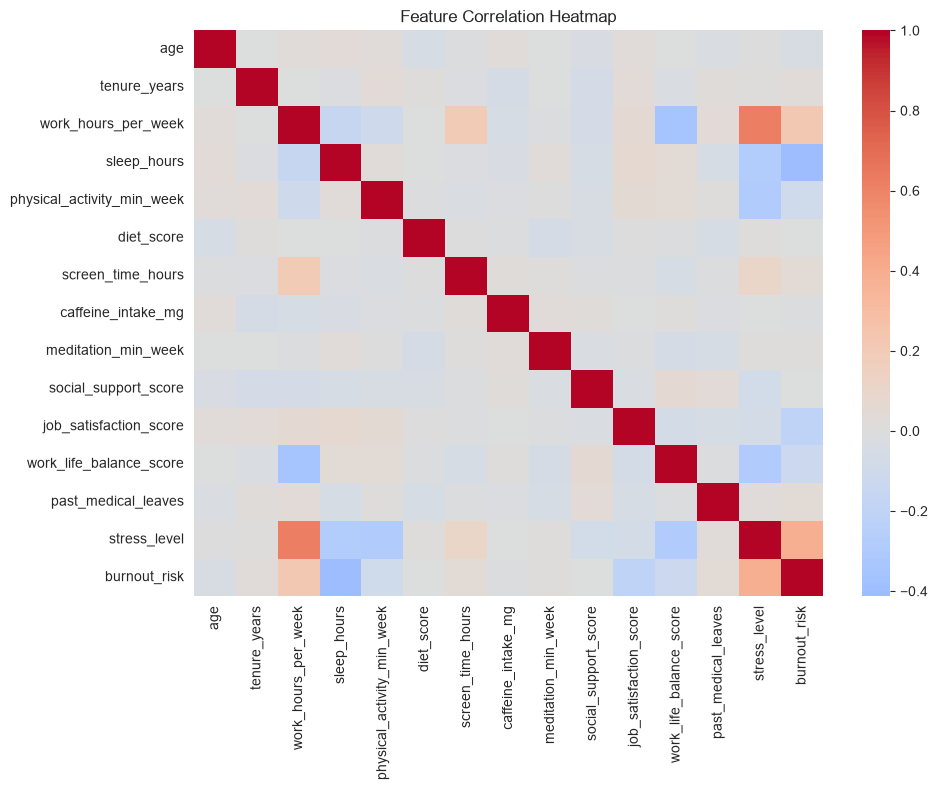

In [9]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[numeric_cols].corr(), cmap="coolwarm", center=0)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

## Department-level patterns

In [7]:
dept_summary = df.groupby("department")[["stress_level", "burnout_risk", "work_hours_per_week", "sleep_hours"]].mean()
dept_summary.sort_values("stress_level", ascending=False)

,stress_level,burnout_risk,work_hours_per_week,sleep_hours
department,,,,
HR,47.610881,0.471503,45.874093,6.436196
Support,47.569588,0.422680,46.160309,6.508182
Operations,47.442512,0.391304,46.339614,6.545075
Sales,47.402871,0.406699,45.780861,6.487171
Engineering,47.360648,0.430556,46.260185,6.499805
Finance,46.814516,0.397849,45.305914,6.524505
